# 고객 이탈 예측 — 분류 모델 고도화 · 검증 및 평가 종합 실습

수업 필기 `고객이탈예측_1` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `모델검증및평가` 18장 — 분류 모델 성능 고도화 검증 및 평가 종합 실습, `머신러닝` v7 p.138~146 — GridSearchCV · RandomizedSearchCV)

- 같은 데이터로 처음 모델을 만든 날은 [Day 026](../../2026-10-15/), 평가 지표 · 특성 중요도 개념은 [Day 029](../../2026-10-20/) 에 정리했습니다. 오늘은 그 둘을 합쳐 **튜닝 → 평가 → 특성 중요도로 검증**까지 한 번에 합니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.
- 회귀 종합 실습(보스턴 집값)은 [`regression_model_evaluation.ipynb`](./regression_model_evaluation.ipynb) 에 있습니다.

> 데이터 : `Telco-Customer-Churn.csv` (통신사 고객 7,043명 × 21열, 정답 `Churn` = 이탈 Yes / No). 컬럼 설명은 [Day 026 의 데이터 설명서](../../2026-10-15/lecture/).

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 데이터 불러오기 · 전처리

In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv('./Telco-Customer-Churn.csv')     # 노트북과 같은 폴더
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 문제점 : TotalCharges 는 숫자여야 하는데 공백 문자열(' ') 이 섞여 문자열로 읽혔다
space_index = df.query("TotalCharges == ' '").index
print("공백인 행 :", space_index.tolist())
print("그 고객들의 가입 기간(tenure) :", df.loc[space_index, 'tenure'].unique())   # 모두 0 → 아직 첫 요금 청구 전

# 1단계 : 문자열 → 숫자 (숫자로 바꿀 수 없는 값은 NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# 2단계 : 누락 행 제거
df1 = df.dropna(ignore_index=True)
print(df.shape, '->', df1.shape)

공백인 행 : [488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754]
그 고객들의 가입 기간(tenure) : [0]
(7043, 21) -> (7032, 21)


> **📝 고친 부분** (`고객이탈예측_1`)
> - 경로 `C:/Users/playdata2/work/...` → 노트북과 같은 폴더 `./Telco-Customer-Churn.csv`
> - `print(space_index)` 셀에 저장된 출력이 없었다(실행 순서가 섞인 흔적) → 공백 11건과 그 고객들이 모두 **`tenure = 0`(신규 가입)** 인 것까지 확인
> - `df.info()` 를 두 번 찍던 것 → `dtype` 변화는 한 줄로 충분, `display(df1)` 7천 행 출력 → 모양만
> - 주석 오타 `변환활` → 변환할
> - `warnings.filterwarnings('ignore')` 를 맨 앞에 두면 **중요한 경고까지 숨는다** — 아래 4장의 `ConvergenceWarning` 이 바로 그 예. 이 노트는 경고를 끄지 않았다.

## 2. EDA — 어떤 고객이 떠나는가

필기의 plotly 그래프 5개(이탈 비율 · 계약 형태 · 가입 기간 · 월 요금 · 총 요금)를 GitHub 에서도 보이도록 matplotlib 한 장으로 그렸다.

{'No': 0.7342, 'Yes': 0.2658}
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48


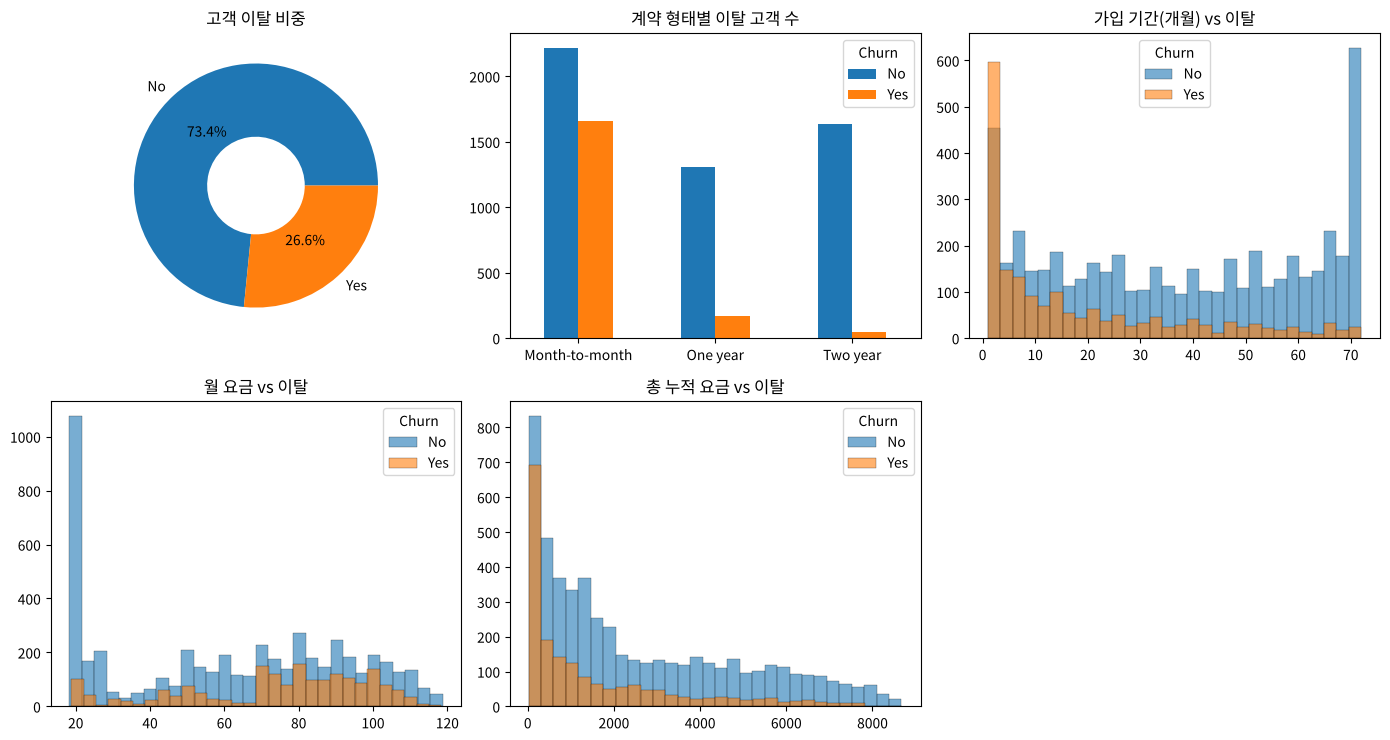

In [4]:
churn_ratio = df1['Churn'].value_counts(normalize=True)
contract = df1.groupby(['Contract', 'Churn']).size().unstack()
print(churn_ratio.round(4).to_dict())
print(contract)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
axes = axes.ravel()
axes[0].pie(churn_ratio, labels=churn_ratio.index, autopct='%.1f%%', wedgeprops=dict(width=0.6))
axes[0].set_title('고객 이탈 비중')
contract.plot.bar(ax=axes[1], rot=0)
axes[1].set_title('계약 형태별 이탈 고객 수'); axes[1].set_xlabel('')
for ax, col, title in zip(axes[2:5], ['tenure', 'MonthlyCharges', 'TotalCharges'],
                          ['가입 기간(개월)', '월 요금', '총 누적 요금']):
    for label in ['No', 'Yes']:
        ax.hist(df1.loc[df1['Churn'] == label, col], bins=30, alpha=0.6, label=label, edgecolor='black', linewidth=0.3)
    ax.set_title(f'{title} vs 이탈'); ax.legend(title='Churn')
axes[5].axis('off')
plt.tight_layout()
plt.show()

- 이탈 **26.6%** → 불균형. 전부 "유지"라고 찍어도 정확도 0.734 (기준선)
- 월 단위 계약은 3,875명 중 1,655명(**42.7%**) 이탈, 2년 계약은 2.8%
- 가입 **초기**에 이탈이 몰리고, 월 요금 70 ~ 105 구간에서 이탈이 많다

## 3. 인코딩 · 분리

In [5]:
df2 = df1.drop(columns=['customerID'])                      # 고객 번호는 예측에 쓸모없음
df2['Churn'] = df2['Churn'].map({'No': 0, 'Yes': 1})        # 정답 : 레이블 인코딩

# 범주형(문자열) 컬럼 이름 → 원-핫 인코딩
categorical_cols = df2.select_dtypes(include=['object', 'string']).columns.tolist()
print(len(categorical_cols), "개 :", categorical_cols)

df_onehot = pd.get_dummies(data=df2, columns=categorical_cols, dtype=int)
print(df2.shape, '->', df_onehot.shape)

15 개 : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(7032, 20) -> (7032, 46)


In [6]:
from sklearn.model_selection import train_test_split

X_data = df_onehot.drop(columns=['Churn'])
y_data = df_onehot['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)
print("X · y 인덱스 짝 :", (X_train.index == y_train.index).all())
print("이탈 비율  전체 / 학습용 / 평가용 :",
      round(y_data.mean(), 4), round(y_train.mean(), 4), round(y_test.mean(), 4))   # stratify 로 같게

학습용 : (5625, 45)  평가용 : (1407, 45)
X · y 인덱스 짝 : True
이탈 비율  전체 / 학습용 / 평가용 : 0.2658 0.2658 0.2658


> **📝 고친 부분**
> - `select_dtypes(include=['object'])` → `['object', 'string']` — pandas 3 에서는 문자열 자료형이 `str` 이라 `'object'` 만 쓰면 경고가 나고 앞으로 못 찾게 된다([Day 020 예시](../../2026-10-06/))
> - 학습용 이탈 비율을 출력하면서 제목은 **"평가용** 데이터의 정답 비율" → 학습용 · 평가용을 나란히

## 4. LogisticRegression(로지스틱 회귀) 모델 — 필기 그대로 (스케일링 없음)

### 4-1. 모델 생성

In [7]:
# 필요한 모델 클래스 임포트
from sklearn.linear_model import LogisticRegression

# 클래스 호출, 모델 생성 (모든 하이퍼파라미터 기본값 : C=1.0, max_iter=100)
lr = LogisticRegression()

### 4-2. 모델 학습 : `fit()`

In [8]:
import warnings

# 필기는 맨 앞에서 경고를 모두 껐다 → 여기서는 학습 중 나온 경고를 '기록'해서 확인
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    lr.fit(X_train, y_train)
print('학습 완료')

print("경고 :", {w.category.__name__ for w in caught})
print("반복 횟수 n_iter_ :", lr.n_iter_, "/ max_iter =", lr.max_iter, " ← 상한까지 돌고도 수렴하지 못했다")

학습 완료
경고 : {'ConvergenceWarning'}
반복 횟수 n_iter_ : [100] / max_iter = 100  ← 상한까지 돌고도 수렴하지 못했다


**`ConvergenceWarning`** — 최적의 가중치를 찾는 계산(lbfgs)이 100번 안에 **수렴하지 못했다**. 필기는 `warnings.filterwarnings('ignore')` 로 이 경고를 숨겨서 몰랐던 것.
원인은 [Day 026](../../2026-10-15/) 과 같다 — `TotalCharges`(0 ~ 8,684)와 0/1 원-핫 컬럼의 **단위 차이**. 수렴하지 못한 모델은 컴퓨터 · 라이브러리 버전마다 결과가 조금씩 달라진다(필기 정확도 0.8053, 이 노트 0.8067).

### 4-3. 학습 완료 후 생성된 계수(가중치) 확인 — 필기의 "특성 중요도"

In [9]:
# 계수의 크기 : model.coef_ → 특성 45개 각각의 가중치 (절댓값)
feature_importances = np.abs(lr.coef_[0])

# 컬럼 이름과 계수의 크기 → DataFrame → 내림차순 정렬
coef_raw = pd.Series(feature_importances, index=X_train.columns).sort_values(ascending=False)
print("필기 방식 상위 5개 :", coef_raw.head(5).round(3).to_dict())

# 숫자 컬럼 3개는 몇 위일까?
print("숫자 컬럼들의 순위 :",
      {c: int(coef_raw.index.get_loc(c)) + 1 for c in ['tenure', 'TotalCharges', 'MonthlyCharges']}, "/ 45")

# 숫자 컬럼들의 범위 — 0/1 원-핫 컬럼과 단위가 전혀 다르다
X_train[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().loc[['min', 'max', 'std']].round(1)

필기 방식 상위 5개 : {'Contract_Month-to-month': 0.451, 'Contract_Two year': 0.35, 'InternetService_DSL': 0.299, 'InternetService_Fiber optic': 0.285, 'PaymentMethod_Electronic check': 0.283}
숫자 컬럼들의 순위 : {'tenure': 35, 'TotalCharges': 45, 'MonthlyCharges': 43} / 45


,tenure,MonthlyCharges,TotalCharges
min,1.0,18.2,18.8
max,72.0,118.8,8684.8
std,24.5,30.0,2263.8


계수는 **특성이 1 단위 늘 때** 의 영향이라, 단위가 큰 특성(1개월 · 1달러)일수록 계수가 작게 나온다. 스케일링(평균 0 · 표준편차 1)한 뒤 학습하면 계수끼리 비교할 수 있다.

In [10]:
# 스케일링 → 로지스틱 회귀를 하나로 묶은 파이프라인
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr_scaled = make_pipeline(StandardScaler(), LogisticRegression())
lr_scaled.fit(X_train, y_train)
print("반복 횟수 :", lr_scaled[-1].n_iter_, " ← 스케일링하면 금방 수렴")

# 파이프라인의 마지막 단계([-1]) = 로지스틱 회귀 모델의 계수 (부호 포함)
coef_scaled = pd.Series(lr_scaled[-1].coef_[0], index=X_train.columns)
top = coef_scaled.abs().sort_values(ascending=False).head(8).index
pd.DataFrame({'계수(부호 포함)': coef_scaled[top].round(3),
              '필기 방식 순위': [int(coef_raw.index.get_loc(c)) + 1 for c in top]})

반복 횟수 : [28]  ← 스케일링하면 금방 수렴


,계수(부호 포함),필기 방식 순위
tenure,-1.478,35
TotalCharges,0.777,45
Contract_Month-to-month,0.285,1
Contract_Two year,-0.273,2
InternetService_Fiber optic,0.164,4
InternetService_DSL,-0.143,3
PaymentMethod_Electronic check,0.130,5
TechSupport_No,0.113,7


| | 필기 (스케일링 X) | 스케일링 O |
|---|---|---|
| 1위 | `Contract_Month-to-month` · `Contract_Two year` | **`tenure`** (−1.48) |
| `tenure` 순위 | 45개 중 **35위** | **1위** |
| `TotalCharges` 순위 | 45개 중 **45위** (꼴찌) | **2위** (+0.78) |

- **부호**도 의미가 있다 : `tenure` 는 **−** (오래 쓴 고객일수록 덜 떠남), `TotalCharges` 는 **+** (같은 기간이면 많이 낸 고객이 더 떠남).
- 원-핫을 모든 값으로 만들면(`Contract_Month-to-month` · `One year` · `Two year`) 셋을 더하면 항상 1 이라 계수가 **서로 나눠 가진다** → 하나만 따로 해석하기 어렵다. 그래서 5-8 에서 **순열 특성 중요도**로 한 번 더 확인한다.

> **📝 고친 부분** — 주석 "학습 완료 후 생성된 최적의 **직선** 기울기" → 로지스틱 회귀에서 계수는 특성 45개 공간의 **결정 경계(초평면)** 방향이고, 계수 하나는 그 특성이 1 늘 때 **log-odds(이탈 확률의 로짓)** 가 얼마나 변하는지다.

### 4-4. 평가용 데이터를 이용한 예측 : `predict()`

In [11]:
pred_test_lr = lr.predict(X_test)
print(pred_test_lr)
print("예측한 이탈(1) 수 :", int(pred_test_lr.sum()), "/ 실제 이탈 :", int(y_test.sum()))

[1 0 0 ... 0 0 0]
예측한 이탈(1) 수 : 310 / 실제 이탈 : 374


### 4-5. 모델 평가 : `accuracy_score()` · `classification_report()`

In [12]:
# 필요한 함수 임포트
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, recall_score, precision_score)

# 평가용 데이터에 대한 정확도
acc_lr = accuracy_score(y_test, pred_test_lr)
print(f'LogisticRegression 모델의 정확도 : {acc_lr:.4f}')

# 4가지 성능 (정밀도 · 재현율 · F1 · 정확도)
print(classification_report(y_test, pred_test_lr, digits=3))

# 앞으로 모든 모델을 같은 기준으로 비교하기 위한 함수 (이탈 = 1 기준)
def scores(model):
    p = model.predict(X_test)
    return {'정확도': accuracy_score(y_test, p), '재현율': recall_score(y_test, p),
            '정밀도': precision_score(y_test, p, zero_division=0), 'F1': f1_score(y_test, p)}

lr_basic = lr       # 아래 5장에서 lr 변수를 새 모델로 바꾸므로, 필기의 기본 모델은 따로 보관

LogisticRegression 모델의 정확도 : 0.8067
              precision    recall  f1-score   support

           0      0.847     0.899     0.872      1033
           1      0.665     0.551     0.602       374

    accuracy                          0.807      1407
   macro avg      0.756     0.725     0.737      1407
weighted avg      0.798     0.807     0.801      1407



## 5. LogisticRegression 분류 모델 고도화

### 5-1. 탐색 도구 생성 및 탐색 실행 — 필기 그대로 (`C` × `max_iter`, `scoring='f1'`)

In [13]:
# 필요한 클래스 임포트
from sklearn.model_selection import GridSearchCV

# 성능 고도화 대상 모델 생성
lr = LogisticRegression(random_state=0)

# 최적화 할 매개 변수와 탐색 조건 → 5 × 4 = 20가지
params = {
    'C': [0.01, 0.1, 1, 10, 100],          # 규제 강도의 역수 (작을수록 강한 규제)
    'max_iter': [100, 500, 1000, 5000],    # 계산 반복 횟수 상한
}

# 탐색 도구 생성 : 이탈(1)을 잘 잡는지 보기 위해 F1 로 비교
grid_lr = GridSearchCV(estimator=lr, param_grid=params, scoring='f1', cv=5)

# 학습 및 검증 (20가지 × 5-fold = 100번 학습)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')        # 100번 학습에서 ConvergenceWarning 이 쏟아지므로 여기서만 끈다
    grid_lr.fit(X_train, y_train)
print("검증 완료")

검증 완료


### 5-2. best 모델 추출 · 검증용 데이터에 대한 최적의 성능

In [14]:
# best 모델 : best 조합 + 학습용 전체로 이미 다시 학습(refit)된 모델
best_lr_note = grid_lr.best_estimator_
print(best_lr_note)

# 검증용(5개 fold) 평균 F1
print("검증 F1 :", round(grid_lr.best_score_, 4))

# 20가지 조합의 검증 F1 표
pd.DataFrame(grid_lr.cv_results_).pivot(index='param_C', columns='param_max_iter', values='mean_test_score').round(4)

LogisticRegression(C=100, max_iter=500, random_state=0)
검증 F1 : 0.5981


param_max_iter,100,500,1000,5000
param_C,,,,
0.01,0.5875,0.5868,0.5857,0.5855
0.10,0.5939,0.5981,0.5963,0.5964
1.00,0.5955,0.5980,0.5952,0.5950
10.00,0.5926,0.5962,0.5952,0.5939
100.00,0.5934,0.5981,0.5960,0.5943


- `max_iter` 는 모델의 성질을 바꾸는 하이퍼파라미터가 아니라 **"몇 번까지 계산하다 멈출지"** 다. 수렴하면 그 뒤로는 아무 차이가 없다(스케일링한 모델은 28번에 수렴).
- 표에서 `max_iter` 에 따라 F1 이 0.59 ~ 0.60 으로 오르내리는 건 **수렴하지 못하고 중간에 멈춘 위치**가 달라서 생기는 잡음이고, best(`C=100, max_iter=500`)도 그 잡음 속 1등일 뿐이다.
- 필기는 best 대신 `C=1, max_iter=500` 으로 **새 모델을 다시 만들어** 학습했다. `best_estimator_` 가 이미 **best 조합 + 학습용 전체로 다시 학습(refit)** 된 모델이므로 따로 만들 필요가 없고, 다른 조합으로 만들면 그건 더 이상 best 가 아니다.

진짜 문제는 **재현율 0.55** — 이탈 고객 374명 중 167명을 놓친다. 이탈이 26.6% 뿐이라 모델이 "유지" 쪽으로 기울기 때문.
그래서 탐색 조건을 바꿔 다시 고도화한다.

### 5-3. 탐색 도구 생성 및 탐색 실행 — 개선 (스케일링 + `C` + `class_weight`)

`class_weight='balanced'` 는 적은 쪽(이탈) 데이터의 **오차에 더 큰 벌점**(0.734 / 0.266 ≈ 2.8배)을 줘서 이탈을 더 적극적으로 잡게 한다.

In [15]:
# 성능 고도화 대상 모델 : 스케일러 + 로지스틱 회귀 (교차 검증 fold 마다 학습용으로만 스케일러 fit)
pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# 최적화 할 매개 변수 : 파이프라인 안의 모델은 '단계이름__매개변수' → 5 × 2 = 10가지
params_lr = {
    'logisticregression__C': [0.01, 0.1, 1, 10, 100],
    'logisticregression__class_weight': [None, 'balanced'],   # None = 기본값 (가중치 없음)
}

# 탐색 도구 생성 및 학습 · 검증 (10가지 × 5-fold = 50번)
grid_lr2 = GridSearchCV(estimator=pipe_lr, param_grid=params_lr, scoring='f1', cv=5)
grid_lr2.fit(X_train, y_train)
print("검증 완료")

검증 완료


### 5-4. best 모델 추출 · 검증용 데이터에 대한 최적의 성능

In [16]:
best_lr = grid_lr2.best_estimator_
print(best_lr)
print("best :", grid_lr2.best_params_, " 검증 F1 :", round(grid_lr2.best_score_, 4))

# C × class_weight 검증 F1 표
r = pd.DataFrame(grid_lr2.cv_results_)
r['class_weight'] = r['param_logisticregression__class_weight'].map(lambda v: 'None' if pd.isna(v) else v)   # 기본값 None 은 결과표에서 NaN → 'None' 으로
r.pivot(index='param_logisticregression__C', columns='class_weight', values='mean_test_score').round(4)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=100, class_weight='balanced',
                                    max_iter=1000))])
best : {'logisticregression__C': 100, 'logisticregression__class_weight': 'balanced'}  검증 F1 : 0.6283


class_weight,None,balanced
param_logisticregression__C,,
0.01,0.5824,0.6242
0.10,0.5921,0.6273
1.00,0.5961,0.6275
10.00,0.5950,0.6280
100.00,0.5955,0.6283


`C` 를 바꿔도 F1 은 0.59 ~ 0.60 에서 거의 그대로(0.01 만 조금 낮음) — 이 데이터에서 규제는 큰 문제가 아니다. **`class_weight='balanced'` 하나가 F1 을 0.596 → 0.628** 로 올렸다.

![C 와 계수 애니메이션](./images/anim_01_lr_c_path.gif)

🎬 `C` 를 0.001 → 100 으로 키우며 스케일링한 로지스틱 회귀의 계수(왼쪽)와 5-fold 검증 F1(오른쪽)을 그렸다. `C` 가 작으면(규제 강함) 계수가 모두 0 쪽으로 눌리고 F1 도 낮다. **`C ≥ 0.1` 부터는 계수 순위도 F1 도 거의 안 변한다** — 그래서 `C` 튜닝 효과가 작았다.

### 5-5. 평가용 데이터를 이용한 예측

In [17]:
pred_test_best_lr = best_lr.predict(X_test)          # 고도화한 모델 (balanced)
pred_test_lr_scaled = lr_scaled.predict(X_test)      # 비교 : 스케일링만 한 기본 모델
print(pred_test_best_lr)
print("예측한 이탈(1) 수 — 기본 :", int(pred_test_lr_scaled.sum()), " / 고도화 :", int(pred_test_best_lr.sum()),
      " / 실제 :", int(y_test.sum()))

[1 1 0 ... 1 0 0]
예측한 이탈(1) 수 — 기본 : 310  / 고도화 : 566  / 실제 : 374


### 5-6. 모델 평가 : 혼동 행렬 · `classification_report()`

In [18]:
for name, p in [('스케일링 + 기본값', pred_test_lr_scaled), ('스케일링 + balanced (고도화)', pred_test_best_lr)]:
    print(f"[{name}]")
    print(confusion_matrix(y_test, p))                    # [[TN FP] [FN TP]]
    print(classification_report(y_test, p, digits=3))

[스케일링 + 기본값]
[[930 103]
 [167 207]]
              precision    recall  f1-score   support

           0      0.848     0.900     0.873      1033
           1      0.668     0.553     0.605       374

    accuracy                          0.808      1407
   macro avg      0.758     0.727     0.739      1407
weighted avg      0.800     0.808     0.802      1407

[스케일링 + balanced (고도화)]
[[764 269]
 [ 77 297]]
              precision    recall  f1-score   support

           0      0.908     0.740     0.815      1033
           1      0.525     0.794     0.632       374

    accuracy                          0.754      1407
   macro avg      0.717     0.767     0.724      1407
weighted avg      0.806     0.754     0.767      1407



| 평가용 1,407명 | 정확도 | 재현율(이탈) | 정밀도(이탈) | F1 | 놓친 이탈 고객 |
|---|---|---|---|---|---|
| 스케일링 + 기본값 | **0.808** | 0.553 | **0.668** | 0.605 | 167명 |
| 스케일링 + `balanced` | 0.754 | **0.794** | 0.525 | **0.632** | **77명** |

- 이탈 고객을 **90명 더** 잡는 대신, 떠나지 않을 고객 166명을 추가로 "이탈 위험"으로 분류한다(정밀도 ↓). 정확도는 떨어진다.
- 어느 쪽이 좋은지는 **비용**으로 정한다 — 이탈 방지 혜택(쿠폰 등)이 싸고 고객 하나를 잃는 손해가 크면 재현율 쪽.

![class_weight 애니메이션](./images/anim_05_class_weight.gif)

🎬 이탈(1) 쪽 가중치를 1 → 5 로 키우면 혼동 행렬에서 **놓친 이탈(FN)** 이 줄고 **잘못 경보(FP)** 가 늘어난다. 재현율은 0.55 → 0.91 로 계속 오르고 정밀도는 0.67 → 0.46 으로 내려간다. F1 은 가중치 **2 ~ 3 사이**에서 가장 높고(2.25 에서 0.643), `balanced`(≈ 2.76, 이탈 비율의 역수)도 그 근처다.

> **📝 고친 부분**
> - `GridSearchCV` 에 원본 `X_train` 을 그대로 넣으면 스케일링이 안 된다. 그렇다고 미리 `StandardScaler().fit_transform(X_train)` 하면 **검증 fold 의 정보가 스케일러에 섞인다** → `make_pipeline` 으로 묶어 fold 마다 학습용으로만 fit.
> - 오타 `LogisticRegession` · `LogisticReression` → **LogisticRegression**, `performace` → performance

### 5-7. 특성 중요도로 모델 검증 — 학습용(계수) vs 평가용(순열) (교재 `모델검증및평가`)

| | 내장 특성 중요도 (계수 · `feature_importances_`) | 순열 특성 중요도 (`permutation_importance`) |
|---|---|---|
| 기준 데이터 | **학습용** (학습하면서 계산) | **평가용** (학습 끝난 모델에) |
| 방법 | 계수 크기 · 분할 기여도(불순도 감소) | 컬럼 하나를 **무작위로 섞었을 때** 성능이 얼마나 떨어지나 |

**판정** : 두 중요도의 **상위권 순위가 비슷하면** → 실전에서도 올바른 근거로 예측(일반화 성공). 학습용에서 높던 특성이 순열 중요도에서 **폭락하거나 음수**면 → 학습 데이터의 잡음을 외운 것(과대적합).

In [19]:
# 필요한 함수 임포트
from sklearn.inspection import permutation_importance

# 학습용 기준 : 고도화한 모델의 계수 크기
coef_best = pd.Series(np.abs(best_lr[-1].coef_[0]), index=X_train.columns)

# 평가용 기준 : 컬럼을 하나씩 10번 섞었을 때 F1 이 얼마나 떨어지나
perm_lr = permutation_importance(best_lr, X_test, y_test, n_repeats=10, random_state=0, scoring='f1')
perm_lr = pd.Series(perm_lr.importances_mean, index=X_test.columns)

check_lr = pd.DataFrame({'학습용(|계수|)': coef_best, '평가용(순열, F1 감소)': perm_lr})
check_lr = check_lr.sort_values('학습용(|계수|)', ascending=False).head(8)
check_lr['순열 순위'] = perm_lr.rank(ascending=False)[check_lr.index].astype(int)
check_lr.round(4)

,학습용(|계수|),"평가용(순열, F1 감소)",순열 순위
tenure,1.4302,0.2063,1
TotalCharges,0.7846,0.0377,2
MonthlyCharges,0.7558,0.0300,3
InternetService_Fiber optic,0.3386,0.0187,4
Contract_Month-to-month,0.2979,-0.0035,44
Contract_Two year,0.2923,0.0050,12
InternetService_DSL,0.2684,0.0089,5
StreamingMovies_Yes,0.1457,0.0077,6


- 학습용 1 ~ 4위 `tenure` · `TotalCharges` · `MonthlyCharges` · `InternetService_Fiber optic` 가 평가용(순열)에서도 **1 ~ 4위** → **안정적으로 검증된 모델**. `tenure` 를 섞으면 평가용 F1 이 **0.21** 이나 떨어진다.
- 예외 : `Contract_Month-to-month` 는 학습용 5위인데 순열은 **44위(−0.004)**. 과대적합이 아니라 **원-핫 중복** 때문이다 — 계약 형태가 컬럼 3개(`Month-to-month` · `One year` · `Two year`)로 나뉘어 있어서, 하나를 섞어도 나머지 두 컬럼으로 계약 형태를 거의 알 수 있다. 순열 중요도는 **서로 겹치는 정보를 가진 특성**의 중요도를 낮게 보여 준다는 한계가 있다.

## 6. SVM 분류 모델 — 필기 그대로 (스케일링 없음)

필기에는 셀만 있고 실행 결과가 없었다. 실행해 보면 [Day 026](../../2026-10-15/) 과 같은 함정이 나온다.

### 6-1. 모델 생성

In [20]:
# 필요한 모델 클래스 임포트
from sklearn.svm import SVC

# 클래스 호출, 모델 생성 (기본값 : kernel='rbf', C=1.0, gamma='scale')
svc = SVC()

### 6-2. 모델 학습 : `fit()`

In [21]:
svc.fit(X_train, y_train)
print('학습 완료')

학습 완료


### 6-3. 평가용 데이터를 이용한 예측 : `predict()`

In [22]:
pred_test_svc = svc.predict(X_test)
print(pred_test_svc)
print("예측값 종류와 개수 :", dict(zip(*np.unique(pred_test_svc, return_counts=True))))   # 전부 0 ?

[0 0 0 ... 0 0 0]
예측값 종류와 개수 : {np.int64(0): np.int64(1407)}


### 6-4. 모델 평가 : `accuracy_score()` · `classification_report()`

In [23]:
acc_svc = accuracy_score(y_test, pred_test_svc)
print(f'SVM 분류 모델의 정확도 : {acc_svc:.4f}  (기준선 = 전부 "유지" : {1 - y_test.mean():.4f})')
print(classification_report(y_test, pred_test_svc, digits=3, zero_division=0))

SVM 분류 모델의 정확도 : 0.7342  (기준선 = 전부 "유지" : 0.7342)
              precision    recall  f1-score   support

           0      0.734     1.000     0.847      1033
           1      0.000     0.000     0.000       374

    accuracy                          0.734      1407
   macro avg      0.367     0.500     0.423      1407
weighted avg      0.539     0.734     0.622      1407



정확도 0.7342 = **기준선** — 1,407명 **전부 "유지"** 라고 찍었다(재현율 0, 이탈을 한 명도 못 잡음). SVM 은 점 사이의 **거리**로 경계를 정하는데, 범위가 0 ~ 8,684 인 `TotalCharges` 가 거리를 독차지해서 나머지 44개 특성이 무시됐기 때문이다. 정확도만 보면 "73%면 괜찮네" 로 넘어가기 쉬운 함정.

## 7. SVM 분류 모델 고도화

### 7-1. 탐색 도구 생성 및 탐색 실행 (스케일링 + `C` × `gamma` × `class_weight`)

| 하이퍼파라미터 | 의미 |
|---|---|
| `C` | 오분류를 얼마나 봐줄지 (작을수록 부드러운 경계) |
| `gamma` | 점 하나의 영향 범위 (클수록 경계가 구불구불 → 과대적합 위험), `'scale'` = 1 / (특성 수 × 분산) |
| `class_weight` | `'balanced'` 면 이탈(1) 오분류에 더 큰 벌점 |

In [24]:
# 성능 고도화 대상 모델 : 스케일러 + SVC
pipe_svc = make_pipeline(StandardScaler(), SVC())

# 최적화 할 매개 변수 → 3 × 3 × 2 = 18가지
params_svc = {
    'svc__C': [0.1, 1, 10],
    'svc__gamma': ['scale', 0.01, 0.1],
    'svc__class_weight': [None, 'balanced'],
}

# 탐색 도구 생성 및 학습 · 검증 (18가지 × 5-fold = 90번, SVC 는 느려서 CPU 코어를 모두 사용)
grid_svc = GridSearchCV(estimator=pipe_svc, param_grid=params_svc, scoring='f1', cv=5, n_jobs=-1)
grid_svc.fit(X_train, y_train)
print("검증 완료")

검증 완료


### 7-2. best 모델 추출 · 검증용 데이터에 대한 최적의 성능

In [25]:
best_svc = grid_svc.best_estimator_
print(best_svc)
print("best :", grid_svc.best_params_, " 검증 F1 :", round(grid_svc.best_score_, 4))

# C · gamma × class_weight 검증 F1 표
r = pd.DataFrame(grid_svc.cv_results_)
r['class_weight'] = r['param_svc__class_weight'].map(lambda v: 'None' if pd.isna(v) else v)
r['gamma'] = r['param_svc__gamma'].map(str)
r.pivot_table(index=['param_svc__C', 'gamma'], columns='class_weight', values='mean_test_score').round(4)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(C=1, class_weight='balanced'))])
best : {'svc__C': 1, 'svc__class_weight': 'balanced', 'svc__gamma': 'scale'}  검증 F1 : 0.6212


class_weight          None  balanced
param_svc__C gamma                  
0.1          0.01   0.5310    0.6097
             0.1    0.3531    0.5982
             scale  0.5015    0.6140
1.0          0.01   0.5606    0.6137
             0.1    0.5219    0.5844
             scale  0.5562    0.6212
10.0         0.01   0.5669    0.6142
             0.1    0.5095    0.5402
             scale  0.5590    0.5925

| 검증 F1 | `class_weight=None` | `'balanced'` |
|---|---|---|
| `C=1, gamma='scale'` (기본값) | 0.556 | **0.621** (best) |
| `C=0.1, gamma=0.1` | 0.353 | 0.598 |
| `C=10, gamma=0.1` | 0.510 | 0.540 |

- 모든 조합에서 **`balanced` 가 None 보다 높다** — 로지스틱 회귀와 같은 결론.
- `gamma=0.1` 은 경계가 너무 구불구불해져서(점 하나의 영향 범위가 좁음) 점수가 낮고, `C` 까지 크면 더 나빠진다 → 과대적합.
- best 는 `C=1, gamma='scale'` = **기본값 그대로 + `balanced`**.

### 7-3. 평가용 데이터를 이용한 예측

In [26]:
svc_scaled = make_pipeline(StandardScaler(), SVC()).fit(X_train, y_train)   # 비교 : 스케일링만 한 기본 SVC
pred_test_svc_scaled = svc_scaled.predict(X_test)
pred_test_best_svc = best_svc.predict(X_test)
print("예측한 이탈(1) 수 — 필기 :", int(pred_test_svc.sum()), " / 스케일링 :", int(pred_test_svc_scaled.sum()),
      " / 고도화 :", int(pred_test_best_svc.sum()), " / 실제 :", int(y_test.sum()))

예측한 이탈(1) 수 — 필기 : 0  / 스케일링 : 263  / 고도화 : 554  / 실제 : 374


### 7-4. 모델 평가 : 혼동 행렬 · `classification_report()`

In [27]:
for name, p in [('스케일링 + 기본값', pred_test_svc_scaled), ('고도화 (best)', pred_test_best_svc)]:
    print(f"[SVC {name}]")
    print(confusion_matrix(y_test, p))
    print(classification_report(y_test, p, digits=3))

[SVC 스케일링 + 기본값]
[[946  87]
 [198 176]]
              precision    recall  f1-score   support

           0      0.827     0.916     0.869      1033
           1      0.669     0.471     0.553       374

    accuracy                          0.797      1407
   macro avg      0.748     0.693     0.711      1407
weighted avg      0.785     0.797     0.785      1407

[SVC 고도화 (best)]
[[764 269]
 [ 89 285]]
              precision    recall  f1-score   support

           0      0.896     0.740     0.810      1033
           1      0.514     0.762     0.614       374

    accuracy                          0.746      1407
   macro avg      0.705     0.751     0.712      1407
weighted avg      0.794     0.746     0.758      1407



### 7-5. 특성 중요도 — 평가용(순열)만 가능

`rbf` 커널 SVM 은 특성 공간을 휘어서 경계를 만들기 때문에 **계수(`coef_`)도 `feature_importances_` 도 없다**. 그래서 평가용 순열 중요도만 구하고, 로지스틱 회귀(5-7)와 순위를 비교한다.

In [28]:
perm_svc = permutation_importance(best_svc, X_test, y_test, n_repeats=5, random_state=0, scoring='f1', n_jobs=-1)
perm_svc = pd.Series(perm_svc.importances_mean, index=X_test.columns).sort_values(ascending=False)

pd.DataFrame({'SVC 순열(F1 감소)': perm_svc.head(8),
              '로지스틱 순열 순위': perm_lr.rank(ascending=False)[perm_svc.head(8).index].astype(int)}).round(4)

,SVC 순열(F1 감소),로지스틱 순열 순위
Contract_Month-to-month,0.0324,44
tenure,0.0095,1
Contract_One year,0.0053,45
InternetService_Fiber optic,0.0043,4
SeniorCitizen,0.0033,16
InternetService_DSL,0.0030,5
TechSupport_No,0.0026,42
PaymentMethod_Credit card (automatic),0.0022,34


- SVC 도 **계약 형태 · `tenure` · 인터넷 서비스(Fiber · DSL)** 가 상위 — 로지스틱 회귀와 같은 근거로 예측한다.
- 다만 로지스틱 회귀에서는 순열 44위였던 `Contract_Month-to-month` 가 SVC 에서는 1위다. 원-핫으로 나뉜 계약 컬럼 3개 중 **어느 컬럼에 정보를 싣느냐**가 모델마다 다르기 때문(같은 "계약 형태" 정보).

## 8. DecisionTree 분류 모델 — 필기 그대로 (기본값)

### 8-1. 모델 생성

In [29]:
# 필요한 모델 클래스 임포트
from sklearn.tree import DecisionTreeClassifier

# 클래스 호출, 모델 생성 (기본값 : max_depth=None → 끝까지 자란다)
dt = DecisionTreeClassifier(random_state=0)

### 8-2. 모델 학습 : `fit()`

In [30]:
dt.fit(X_train, y_train)
print('학습 완료')
print("트리 깊이 :", dt.get_depth(), " 리프 수 :", dt.get_n_leaves())

학습 완료
트리 깊이 : 27  리프 수 : 1105


### 8-3. 평가용 데이터를 이용한 예측 : `predict()`

In [31]:
pred_test_dt = dt.predict(X_test)
print(pred_test_dt)

[1 0 0 ... 1 0 0]


### 8-4. 모델 평가 : `accuracy_score()` — 학습용 vs 평가용

In [32]:
acc_dt_train = accuracy_score(y_train, dt.predict(X_train))
acc_dt = accuracy_score(y_test, pred_test_dt)
print(f'DecisionTree 학습용 정확도 : {acc_dt_train:.4f}')
print(f'DecisionTree 평가용 정확도 : {acc_dt:.4f}  ← 기준선(0.7342)보다도 낮다')
print(classification_report(y_test, pred_test_dt, digits=3))

dt_basic = dt       # 아래 9장에서 dt 변수를 새 모델로 바꾸므로 따로 보관

DecisionTree 학습용 정확도 : 0.9977
DecisionTree 평가용 정확도 : 0.7193  ← 기준선(0.7342)보다도 낮다
              precision    recall  f1-score   support

           0      0.810     0.807     0.809      1033
           1      0.472     0.476     0.474       374

    accuracy                          0.719      1407
   macro avg      0.641     0.642     0.641      1407
weighted avg      0.720     0.719     0.720      1407



깊이 27, 학습용 **0.998** → 평가용 **0.719** : 학습용을 거의 다 외운 **과대적합**.

### 8-5. 특성 중요도로 과대적합 판정 — 학습용(내장) vs 평가용(순열)

In [33]:
# 학습용 기준 · 평가용 기준 특성 중요도를 나란히 보는 함수
def crosscheck(model, n=6):
    builtin = pd.Series(model.feature_importances_, index=X_train.columns)        # 학습용 : 불순도 감소 기여도
    perm = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=0)
    perm = pd.Series(perm.importances_mean, index=X_test.columns)                   # 평가용 : 섞었을 때 정확도 감소
    top = builtin.sort_values(ascending=False).head(n).index
    return pd.DataFrame({'학습용(내장)': builtin[top], '평가용(순열)': perm[top]}).round(4)

crosscheck(dt)

,학습용(내장),평가용(순열)
TotalCharges,0.2033,0.0190
MonthlyCharges,0.1841,0.0049
Contract_Month-to-month,0.1667,0.0183
tenure,0.1147,0.0415
InternetService_Fiber optic,0.0462,0.0148
PaymentMethod_Electronic check,0.0210,-0.0054


| 기본값 트리 (깊이 27) | 학습용(내장) | 평가용(순열) |
|---|---|---|
| `TotalCharges` | **0.203 (1위)** | 0.019 |
| `MonthlyCharges` | **0.184 (2위)** | **0.005** ← 폭락 |
| `PaymentMethod_Electronic check` | 0.021 | **−0.005** ← 음수 |

학습용에서는 월 요금 · 총 요금으로 고객 하나하나를 **잘게 쪼개 외웠지만**, 평가용에서는 그 컬럼을 섞어도 성능이 거의 안 떨어진다 = 그 분할들은 **잡음**이었다 → 교재의 **"과대적합된 불량 모델"**.

![특성 중요도 교차 검증 애니메이션](./images/anim_02_importance_crosscheck.gif)

🎬 결정 트리 깊이를 2 → 20 으로 키우며 **내장 중요도(학습용, 왼쪽)** 와 **순열 중요도(평가용, 오른쪽)** 를 나란히 그렸다. 깊어질수록 왼쪽에서는 `MonthlyCharges` · `TotalCharges` 가 커지는데 오른쪽에서는 따라오지 않는다 — 두 그래프가 **어긋나기 시작하는 곳이 과대적합의 신호**.

## 9. DecisionTree 분류 모델 고도화

### 9-1. 탐색 도구 생성 및 탐색 실행 (`max_depth` × `min_samples_leaf` × `class_weight`)

트리는 기준값으로 나누기만 하므로 **스케일링이 필요 없다**.

In [34]:
# 성능 고도화 대상 모델 생성
dt = DecisionTreeClassifier(random_state=0)

# 최적화 할 매개 변수 → 9 × 5 × 2 = 90가지
params_dt = {
    'max_depth': range(2, 11),                    # 사전 가지치기 : 최대 깊이
    'min_samples_leaf': [1, 5, 10, 20, 50],       # 리프의 최소 샘플 수 (1 = 기본값)
    'class_weight': [None, 'balanced'],
}

# 탐색 도구 생성 및 학습 · 검증 (90가지 × 5-fold = 450번)
grid_dt = GridSearchCV(estimator=dt, param_grid=params_dt, scoring='f1', cv=5)
grid_dt.fit(X_train, y_train)
print("검증 완료")

검증 완료


### 9-2. best 모델 추출 · 검증용 데이터에 대한 최적의 성능

In [35]:
best_dt = grid_dt.best_estimator_
print(best_dt)
print("best :", grid_dt.best_params_, " 검증 F1 :", round(grid_dt.best_score_, 4))

# class_weight 별로 가장 좋았던 조합
r = pd.DataFrame(grid_dt.cv_results_)
r['class_weight'] = r['param_class_weight'].map(lambda v: 'None' if pd.isna(v) else v)
r.sort_values('mean_test_score', ascending=False).groupby('class_weight').head(1)[
    ['class_weight', 'param_max_depth', 'param_min_samples_leaf', 'mean_test_score']].round(4)

DecisionTreeClassifier(class_weight='balanced', max_depth=7,
                       min_samples_leaf=50, random_state=0)
best : {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 50}  검증 F1 : 0.6243


,class_weight,param_max_depth,param_min_samples_leaf,mean_test_score
74,balanced,7,50,0.6243
16,None,5,5,0.5794


### 9-3. 평가용 데이터를 이용한 예측

In [36]:
pred_test_best_dt = best_dt.predict(X_test)
print(pred_test_best_dt)
print("예측한 이탈(1) 수 — 기본값 :", int(pred_test_dt.sum()), " / 고도화 :", int(pred_test_best_dt.sum()),
      " / 실제 :", int(y_test.sum()))

[1 1 0 ... 0 0 0]
예측한 이탈(1) 수 — 기본값 : 377  / 고도화 : 564  / 실제 : 374


### 9-4. 모델 평가 : 혼동 행렬 · `classification_report()`

In [37]:
print("학습용 정확도 :", round(accuracy_score(y_train, best_dt.predict(X_train)), 4),
      " / 평가용 정확도 :", round(accuracy_score(y_test, pred_test_best_dt), 4))
print(confusion_matrix(y_test, pred_test_best_dt))
print(classification_report(y_test, pred_test_best_dt, digits=3))

학습용 정확도 : 0.7685  / 평가용 정확도 : 0.7498
[[762 271]
 [ 81 293]]
              precision    recall  f1-score   support

           0      0.904     0.738     0.812      1033
           1      0.520     0.783     0.625       374

    accuracy                          0.750      1407
   macro avg      0.712     0.761     0.719      1407
weighted avg      0.802     0.750     0.762      1407



### 9-5. 특성 중요도로 검증 — 학습용(내장) vs 평가용(순열)

In [38]:
crosscheck(best_dt)

,학습용(내장),평가용(순열)
Contract_Month-to-month,0.5745,0.0277
tenure,0.1242,0.0213
InternetService_Fiber optic,0.0886,0.0561
MonthlyCharges,0.0536,-0.0006
TotalCharges,0.0460,-0.0140
PaymentMethod_Electronic check,0.0222,0.0041


- 학습용 1 ~ 3위 **`Contract_Month-to-month` · `tenure` · `InternetService_Fiber optic`** 는 평가용(순열)에서도 상위 → 핵심 근거는 일반화됐다.
- 그런데 `MonthlyCharges`(학습용 0.054 → 평가용 **−0.001**) · `TotalCharges`(0.046 → **−0.014**)는 평가용에서 **음수** — 깊이 7 트리가 요금 컬럼으로 한 분할들은 아직 **잡음**이다. 기본값 트리(요금 컬럼이 학습용 1 · 2위)보다 훨씬 나아졌지만, 교재 기준으로는 요금 분할을 더 줄이는(깊이 ↓ · `min_samples_leaf` ↑) 여지가 남아 있다.

## 10. 정리 — 같은 평가용 1,407명

In [39]:
results = pd.DataFrame({
    'LogisticRegression (필기, 스케일링 X)': scores(lr_basic),
    'LogisticRegression (스케일링)': scores(lr_scaled),
    'LogisticRegression (고도화 : 스케일링 + balanced)': scores(best_lr),
    'SVC (필기, 스케일링 X)': scores(svc),
    'SVC (스케일링)': scores(svc_scaled),
    'SVC (고도화)': scores(best_svc),
    'DecisionTree (필기, 기본값)': scores(dt_basic),
    'DecisionTree (고도화)': scores(best_dt),
}).T.round(4)
results.sort_values('F1', ascending=False)

,정확도,재현율,정밀도,F1
LogisticRegression (고도화 : 스케일링 + balanced),0.7541,0.7941,0.5247,0.6319
DecisionTree (고도화),0.7498,0.7834,0.5195,0.6247
SVC (고도화),0.7456,0.7620,0.5144,0.6142
LogisticRegression (스케일링),0.8081,0.5535,0.6677,0.6053
"LogisticRegression (필기, 스케일링 X)",0.8067,0.5508,0.6645,0.6023
SVC (스케일링),0.7974,0.4706,0.6692,0.5526
"DecisionTree (필기, 기본값)",0.7193,0.4759,0.4721,0.4740
"SVC (필기, 스케일링 X)",0.7342,0.0000,0.0000,0.0000


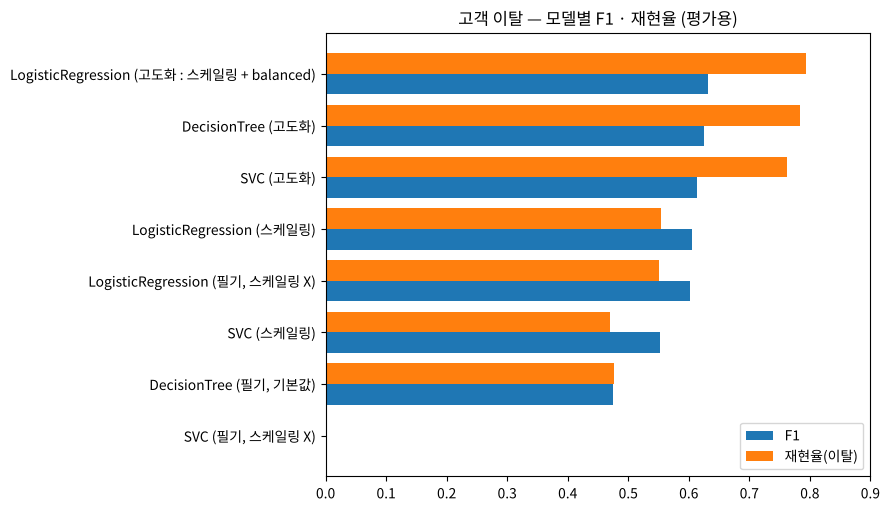

In [40]:
fig, ax = plt.subplots(figsize=(9, 5.2))
res = results.sort_values('F1')
y = np.arange(len(res))
ax.barh(y - 0.2, res['F1'], height=0.4, label='F1')
ax.barh(y + 0.2, res['재현율'], height=0.4, label='재현율(이탈)')
ax.set_yticks(y, res.index)
ax.set_xlim(0, 0.9); ax.legend(loc='lower right')
ax.set_title('고객 이탈 — 모델별 F1 · 재현율 (평가용)')
plt.tight_layout()
plt.show()

![모델 비교](./images/06_churn_model_comparison.png)

| 평가용 1,407명 | 정확도 | 재현율(이탈) | 정밀도 | F1 |
|---|---|---|---|---|
| **로지스틱 회귀 고도화** (스케일링 + `balanced`, `C=100`) | 0.754 | **0.794** | 0.525 | **0.632** |
| 결정 트리 고도화 (`balanced`, 깊이 7, 리프 50) | 0.750 | 0.783 | 0.520 | 0.625 |
| SVC 고도화 (스케일링 + `balanced`, `C=1`) | 0.746 | 0.762 | 0.514 | 0.614 |
| 로지스틱 회귀 (스케일링, 기본값) | **0.808** | 0.553 | **0.668** | 0.605 |
| 결정 트리 (필기, 기본값) | 0.719 | 0.476 | 0.472 | 0.474 |
| SVC (필기, 스케일링 X) | 0.734 | 0 | 0 | 0 |

- 이탈 예측은 **불균형** 문제라 정확도보다 **재현율 · F1** 로 비교한다. 정확도 1등(로지스틱 기본, 0.808)과 F1 1등(로지스틱 고도화, 0.632)이 다르다.
- 세 모델 모두 고도화의 핵심은 같았다 — **스케일링(로지스틱 · SVC)** 과 **`class_weight='balanced'`**. `C` · `gamma` · `max_depth` 같은 하이퍼파라미터보다 효과가 훨씬 컸다.
- 고도화 후 세 모델의 F1 이 0.61 ~ 0.63 으로 비슷하다 → 이 데이터에서는 가장 단순하고 설명하기 쉬운 **로지스틱 회귀**를 고른다.
- 모델을 고른 뒤에는 **학습용 vs 평가용 특성 중요도**로 근거를 확인한다 — 세 모델 모두 **가입 기간 · 계약 형태 · 인터넷 서비스 종류**가 이탈의 핵심 근거.